# Introduction to OpenCV

Computer Vision is a technique that allows us to understand images and videos and extract meaningful information from them. It is a subset of artificial intelligence (AI) that processes digital images or videos to gather data for analysis.

OpenCV is an open-source computer vision and machine learning library. It allows us to process images and videos, detect objects, faces, and even handwriting. Using Python and OpenCV, we can perform everything from basic image transformations to advanced computer vision tasks like feature extraction and object detection.

Python OpenCV is the most popular library for computer vision. Using OpenCV, we can:
* Process images and videos
* Detect objects, faces, and even handwriting
* Perform image transformations like resizing, cropping, rotating, and drawing

When integrated with libraries such as NumPy, Python can efficiently manipulate OpenCV’s array-based image structures for deeper analysis.


---


Why Learn OpenCV?

* Comprehensive Image Processing: OpenCV provides a wide range of functions to manipulate and analyze images, making it ideal for many applications.
* Real-Time Video Processing: Supports video capture and real-time video analysis.
* Cross-Platform: Works on Windows, Linux, macOS, and Android.
* Open-Source: Free to use with a large supportive community.
* Integration with Deep Learning: Can be combined with libraries like TensorFlow and PyTorch for advanced applications.

## Downloading and Installing OpenCV:
OpenCV can be directly downloaded and installed with the use of pip (package manager). To install OpenCV, just go to the command-line and type the following command:



```
pip install opencv-python
```


In [ ]:
!pip install opencv-python

To check if OpenCV is correctly installed, just run the following commands to perform a version check:

In [1]:
import cv2
print(cv2.__version__)

4.13.0




---

<font color="red" size =3>**Before working with OpenCV, we need to upload or download images to the "/content" folder.**</font>





---


## Getting Started with OpenCV

## Reading Images

To read the images cv2.imread() method is used. This method loads an image from the specified file. If the image cannot be read (because of the missing file, improper permissions, unsupported or invalid format) then this method returns an empty matrix.

Image Used:


In [4]:
# Python code to read image
import cv2

# To read image from disk, we use
# cv2.imread function, in below method,
img = cv2.imread("my_image.jpg", cv2.IMREAD_COLOR)

## Displaying Images

**cv2.imshow()** method is used to display an image in a window. The window automatically fits the image size

<font color="red" size =3>**cv2.imshow(WindowName,img) does not work in Google Colab. Colab (and Jupyter Notebooks) cannot open new GUI windows like your local Python environment.**</font>

<font color="red" size =3>Solution: Use cv2_imshow in Colab</font>

<font color="red" size =3> Google Colab provides a special function to display images inside the notebook itself:

from google.colab.patches import cv2_imshow  # Use this instead of cv2.imshow
</font>







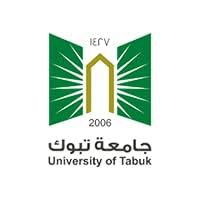

In [5]:
# Python code to read image

import cv2
from google.colab.patches import cv2_imshow  # Use this instead of cv2.imshow

# To read image from disk, we use
# cv2.imread function, in below method,
img = cv2.imread("my_image.jpg", cv2.IMREAD_COLOR)

# Creating GUI window to display an image on screen
# first Parameter is windows title (should be in string format)
# Second Parameter is image array
cv2_imshow(img)


# To hold the window on screen, we use cv2.waitKey method
# Once it detected the close input, it will release the control
# To the next line
# First Parameter is for holding screen for specified milliseconds
# It should be positive integer. If 0 pass an parameter, then it will
# hold the screen until user close it.
cv2.waitKey(0)

# It is for removing/deleting created GUI window from screen
# and memory
cv2.destroyAllWindows()


## Saving Images

cv2.imwrite() method is used to save an image to any storage device. This will save the image according to the specified format in the current working directory.


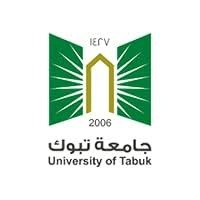

In [6]:
# Python program to explain cv2.imwrite() method

import cv2
from google.colab.patches import cv2_imshow  # Use this instead of cv2.imshow

image_path = 'my_image.jpg'

# Using cv2.imread() method
# to read the image
img = cv2.imread(image_path)

# Filename
filename = 'savedImage.jpg'

# Using cv2.imwrite() method
# Saving the image
cv2.imwrite(filename, img)

# Reading and showing the saved image
img = cv2.imread(filename)
cv2_imshow(img)

cv2.waitKey(0)
cv2.destroyAllWindows()

## Rotating Images

cv2.rotate() method is used to rotate a 2D array in multiples of 90 degrees. The function cv::rotate rotates the array in three different ways.

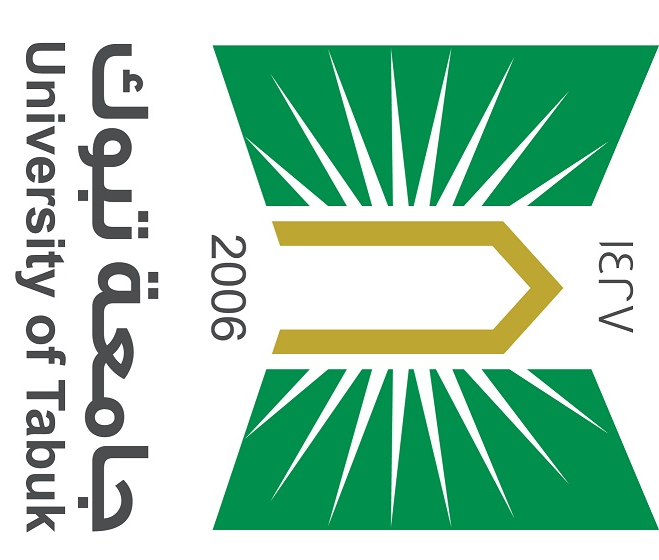

-1

In [ ]:
# Python program to explain cv2.rotate() method

import cv2
from google.colab.patches import cv2_imshow  # Use this instead of cv2.imshow

# path
path = 'savedImage.jpg'

# Reading an image in default mode
src = cv2.imread(path)

# Using cv2.rotate() method
# Using cv2.ROTATE_90_CLOCKWISE rotate
# by 90 degrees clockwise
image = cv2.rotate(src, cv2.ROTATE_90_CLOCKWISE)

# Displaying the image
cv2_imshow(image)
cv2.waitKey(0)

The above functions restrict us to rotate the image in the multiple of 90 degrees only. We can also rotate the image to any angle by defining the rotation matrix listing rotation point, degree of rotation, and the scaling factor.

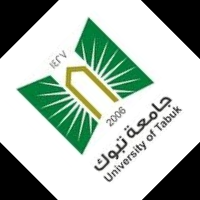

In [14]:
import cv2
from google.colab.patches import cv2_imshow  # Use this instead of cv2.imshow

import numpy as np

FILE_NAME = 'savedImage.jpg'

# Read image from the disk.
img = cv2.imread(FILE_NAME)

# Shape of image in terms of pixels.
(rows, cols) = img.shape[:2]

# getRotationMatrix2D creates a matrix needed
# for transformation. We want matrix for rotation
# w.r.t center to 45 degree without scaling.
M = cv2.getRotationMatrix2D((cols / 2, rows / 2), 45, 1)
res = cv2.warpAffine(img, M, (cols, rows))

cv2_imshow(res)

cv2.waitKey(0)
cv2.destroyAllWindows()

```
cv2.getRotationMatrix2D(center, angle, scale)
```
Parameters explained
center = (cols / 2, rows / 2)
This is the center of rotation.
*   cols → image width
*   rows → image height
So the image rotates around its center, not the top-left corner.

angle = 45
Rotation angle in degrees.
*   Positive → counterclockwise
*   Negative → clockwise

scale = 1
Scale factor.
*   1 → no scaling
*   \> 1 → zoom in
*   \< 1 → zoom out

## Resizing Image

Image resizing refers to the scaling of images. It helps in reducing the number of pixels from an image and that has several advantages e.g. It can reduce the time of training of a neural network as more is the number of pixels in an image more is the number of input nodes that in turn increases the complexity of the model. It also helps in zooming in images. Many times we need to resize the image i.e. either shrink it or scale up to meet the size requirements.

OpenCV provides us with several interpolation methods for resizing an image. Choice of Interpolation Method for Resizing -

*   cv2.INTER_AREA: This is used when we need to shrink an image.


```
small_img = cv2.resize(img, (100, 100), interpolation=cv2.INTER_AREA)
```


*   cv2.INTER_CUBIC: This is used when need to zoom an image, it is slow but more efficient.


```
big_img = cv2.resize(img, (500, 500), interpolation=cv2.INTER_CUBIC)
```


*   cv2.INTER_LINEAR: This is primarily used when zooming is required. This is the default interpolation technique in OpenCV.


```
zoomed_img = cv2.resize(img, (300, 300), interpolation=cv2.INTER_LINEAR)
```



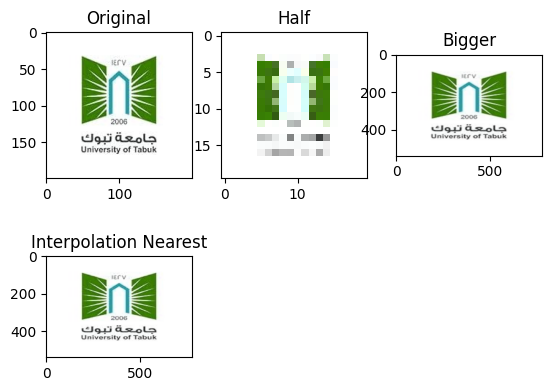

In [18]:
import cv2
from google.colab.patches import cv2_imshow  # Use this instead of cv2.imshow
import numpy as np
import matplotlib.pyplot as plt

image = cv2.imread("savedImage.jpg", 1)
# Loading the image

half = cv2.resize(image, (0, 0), fx = 0.1, fy = 0.1) # scale the width and height by 0.1 → shrink to 10% of the original size. Default interpolation = cv2.INTER_LINEAR
bigger = cv2.resize(image,(780, 540)) # target width and height (note: width first, height second). Default interpolation = cv2.INTER_LINEAR

'''
INTER_NEAREST = nearest-neighbor interpolation.
Fastest method, but can look pixelated or blocky when enlarging.
Useful for simple graphics, masks, or categorical images (like labels) where you don’t want interpolation to mix pixel values.
'''
stretch_near = cv2.resize(image, (780, 540),
            interpolation = cv2.INTER_NEAREST)


Titles =["Original", "Half", "Bigger", "Interpolation Nearest"]
images =[image, half, bigger, stretch_near]
count = 4

for i in range(count):
    plt.subplot(2, 3, i + 1)
    plt.title(Titles[i])
    plt.imshow(images[i])

plt.show()



```
cv2.resize(src, dsize, fx, fy)
```



```
half = cv2.resize(image, (0, 0), fx = 0.1, fy = 0.1)
```

Parameter explanation:

**image:** The original input image.

**(0, 0):** Means the target size is not specified explicitly. OpenCV will compute the new size using the scale factors.

**fx = 0.1** :  Scale factor for the width. The new width = original width × 0.1.

**fy = 0.1** :  Scale factor for the height. The new height = original height × 0.1.

**Default interpolation** : cv2.INTER_LINEAR, which provides a good balance between speed and quality.




```
bigger = cv2.resize(image, (1050, 1610))
```
It resizes the image to a fixed size.

Parameter explanation:

**image** : The original image.

**(1050, 1610)** : Target size:
* 1050 → width
* 1610 → height

<font color="red" size =3>In OpenCV, the order is always: (width, height) </font>


# Color Spaces

Color spaces are a way to represent the color channels present in the image that gives the image that particular hue. There are several different color spaces and each has its own significance. Some of the popular color spaces are RGB (Red, Green, Blue), CMYK (Cyan, Magenta, Yellow, Black), HSV (Hue, Saturation, Value), etc.

 cv2.cvtColor() method is used to convert an image from one color space to another. There are more than 150 color-space conversion methods available in OpenCV.

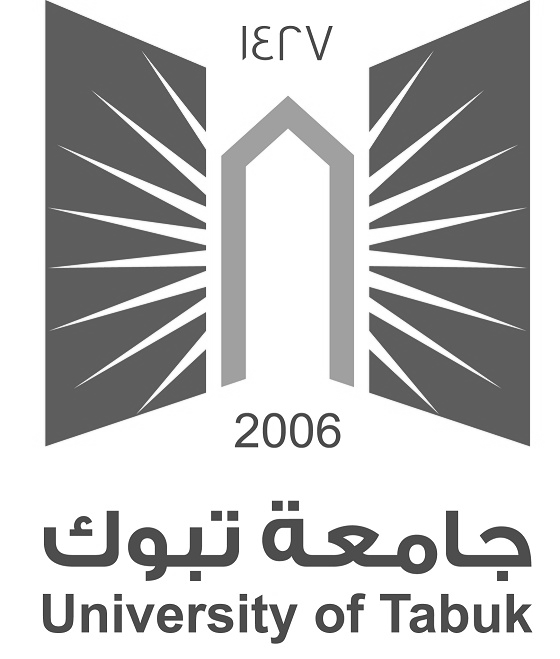

In [ ]:
# Python program to explain cv2.cvtColor() method

# importing cv2
import cv2
from google.colab.patches import cv2_imshow  # Use this instead of cv2.imshow

# path
path = 'savedImage.jpg'

# Reading an image in default mode
src = cv2.imread(path)

# Using cv2.cvtColor() method
# Using cv2.COLOR_BGR2GRAY color space
# conversion code
image = cv2.cvtColor(src, cv2.COLOR_BGR2GRAY )

# Displaying the image
cv2_imshow(image)

cv2.waitKey(0)
cv2.destroyAllWindows()

## Draw Shapes

Learn drawing functions


**Colors are in BGR format (not RGB)**
Thickness:
* 2, 3, 5 → outline
* -1 → filled shape

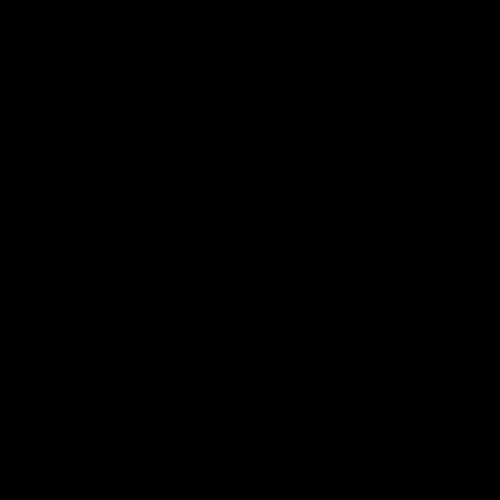

In [42]:
# Create blank image

import cv2
from google.colab.patches import cv2_imshow  # Use this instead of cv2.imshow
import numpy as np

img = np.zeros((500, 500, 3), dtype=np.uint8)
cv2_imshow(img)

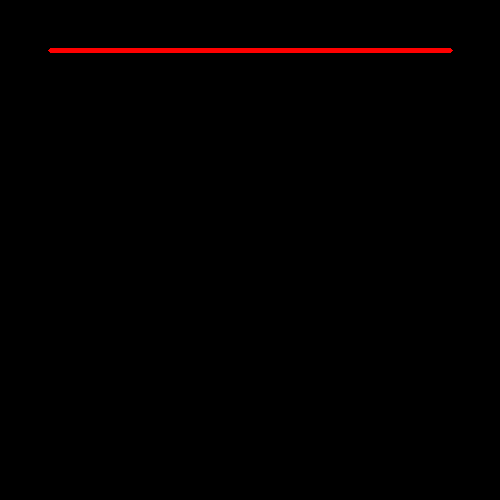

In [43]:
# Draw Line
img = cv2.line(img, (50, 50), (450, 50), (0, 0, 255), 3)

# Red line (BGR format)

cv2_imshow(img)

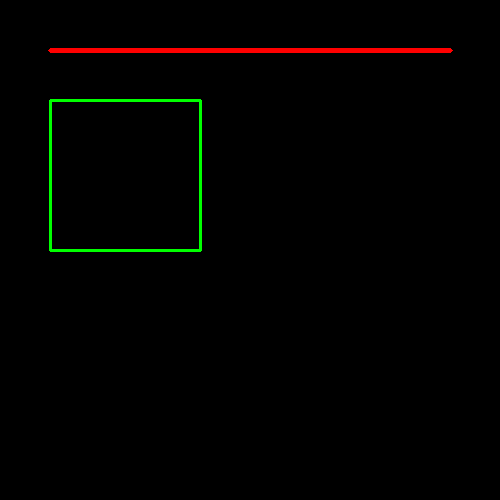

In [44]:
# Draw Rectangle

img = cv2.rectangle(img, (50, 100), (200, 250), (0, 255, 0), 2)

# Green rectangle

cv2_imshow(img)

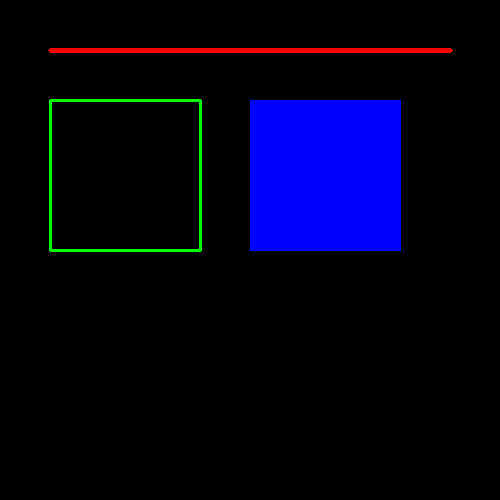

In [45]:
# Filled Rectangle
img = cv2.rectangle(img, (250, 100), (400, 250), (255, 0, 0), -1)

# -1 = filled shape

cv2_imshow(img)

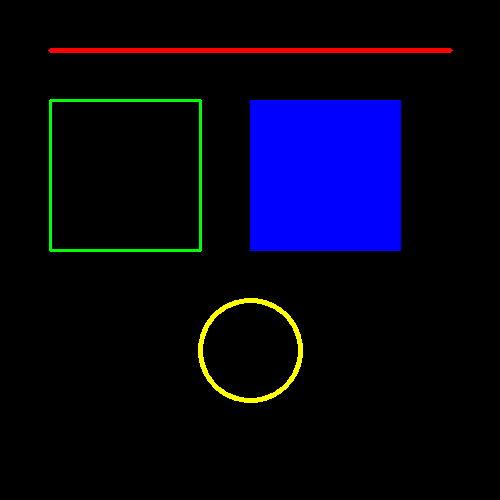

In [46]:
# Draw Circle
img = cv2.circle(img, (250, 350), 50, (0, 255, 255), 3)

cv2_imshow(img)

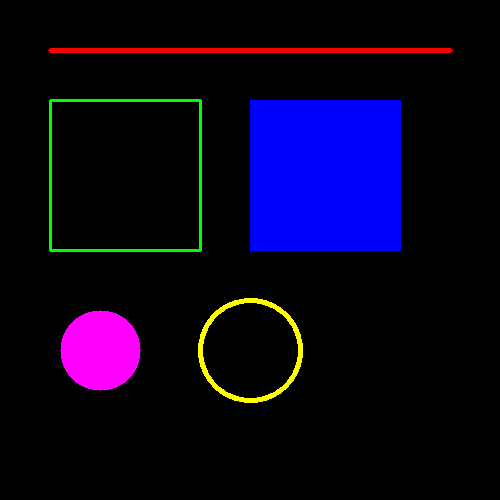

In [47]:
# Filled Circle
img = cv2.circle(img, (100, 350), 40, (255, 0, 255), -1)

cv2_imshow(img)

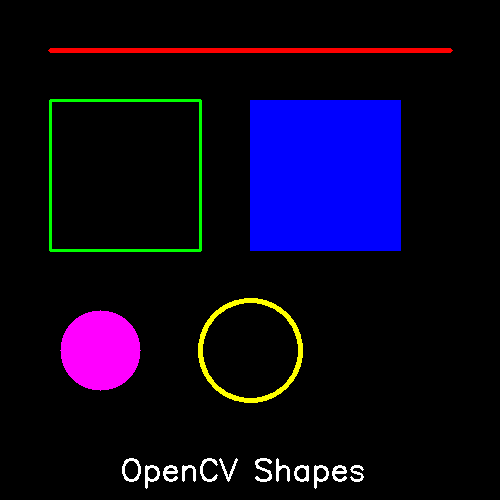

In [48]:
# Draw Text
img  = cv2.putText(img, "OpenCV Shapes", (120, 480),
            cv2.FONT_HERSHEY_SIMPLEX, 1, (255,255,255), 2)


cv2_imshow(img)

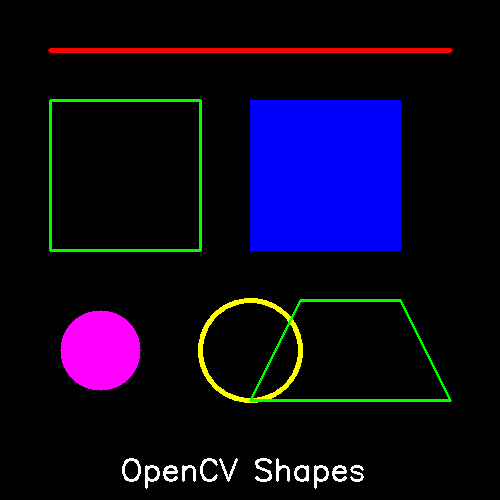

In [ ]:
# Draw Polygon
pts = np.array([[300,300], [400,300], [450,400], [250,400]], np.int32)
pts = pts.reshape((-1, 1, 2))

img = cv2.polylines(img, [pts], True, (0, 255, 0), 2)

cv2_imshow(img)

## Arithmetic Operations
Arithmetic Operations like Addition, Subtraction, and Bitwise Operations can be applied to the input images. These operations can be helpful in enhancing the properties of the input images. Image arithmetics are important for analyzing the input image properties. The operated images can be further used as an enhanced input image, and many more operations can be applied for clarifying, thresholding, dilating, etc of the image.

### Addition of Image:
We can add two images by using function cv2.add(). This directly adds up image pixels in the two images. But adding the pixels is not an ideal situation. So, we use cv2.addweighted(). Remember, both images should be of equal size and depth.

<font color="blue" size =3>1. result = cv2.add(img1, img2) — Direct Addition </font>

How it works:

* It adds each corresponding pixel from the two images.
* The addition is done pixel by pixel.
```
Pixel in img1 = 120
Pixel in img2 = 150
Result = 270
```
* Pixel values in images are usually 0–255.
* OpenCV applies saturation, so any value >255 is clipped to 255.

Result:

* The image can appear too bright
* Some details may be lost

So, this method is often not ideal.




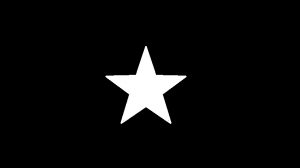

In [ ]:
# Python program to illustrate
# arithmetic operation of
# addition of two images

# organizing imports
import cv2
from google.colab.patches import cv2_imshow  # Use this instead of cv2.imshow
import numpy as np

# path to input images are specified and
# images are loaded with imread command
image1 = cv2.imread('star.jpg')
image2 = cv2.imread('dot.jpg')

# cv2.addWeighted is applied over the
# image inputs with applied parameters
Sum = cv2.add(image1 , image2)

# the window showing output image
# with the weighted sum
cv2_imshow(Sum)

<font color="blue" size =3> **2. result = cv2.addWeighted(img1, α, img2, β, γ)** </font>

Mathematical formula:

output = ( α × img1 ) + (β × img2 ) + γ

Parameters:

* α (alpha) → weight of the first image

* β (beta) → weight of the second image

* γ (gamma) → scalar added to all pixels (usually 0)



```
blended = cv2.addWeighted(img1, 0.7, img2, 0.3, 0)
```
* 70% of the first image

* 30% of the second image

Result:

* Smooth transition between the two images
* Controlled brightness and intensity
* More natural-looking image


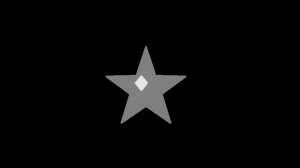

In [ ]:
# Python program to illustrate
# arithmetic operation of
# addition of two images

# organizing imports
import cv2
from google.colab.patches import cv2_imshow  # Use this instead of cv2.imshow
import numpy as np

# path to input images are specified and
# images are loaded with imread command
image1 = cv2.imread('star.jpg')
image2 = cv2.imread('dot.jpg')

# cv2.addWeighted is applied over the
# image inputs with applied parameters
weightedSum = cv2.addWeighted(image1, 0.5, image2, 0.4, 0)

# the window showing output image
# with the weighted sum
cv2_imshow(weightedSum)

## Subtraction of Image:
Just like in addition, we can subtract the pixel values in two images and merge them with the help of cv2.subtract(). The images should be of equal size and depth.

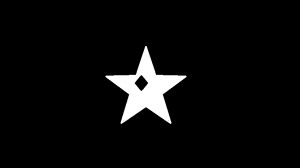

In [ ]:
# Python program to illustrate
# arithmetic operation of
# subtraction of pixels of two images

# organizing imports
import cv2
from google.colab.patches import cv2_imshow  # Use this instead of cv2.imshow
import numpy as np

# path to input images are specified and
# images are loaded with imread command
image1 = cv2.imread('star.jpg')
image2 = cv2.imread('dot.jpg')

# cv2.subtract is applied over the
# image inputs with applied parameters
sub = cv2.subtract(image1, image2)

# the window showing output image
# with the subtracted image
cv2_imshow(sub)

# Edge Detection
What is Edge Detection?

An edge is where the image changes suddenly in brightness or color.

Example:

* Object boundary
* Shape outline
* Text borders

So edge detection means:

Finding the “outlines” of objects in an image

## What is Canny Edge Detection?

The Canny algorithm is a multi-step method to detect edges cleanly and accurately.

How it works (simple explanation)
1. Noise removal
  * Image is blurred first
  * Removes small random noise

2. Gradient detection
  * Finds where brightness changes sharply
  * These are potential edges

3. Non-maximum suppression
  * Keeps only the strongest edges
  * Removes weak blurry edges

4. Thresholding (very important)
  * Decides which edges are real

```
edges = cv2.Canny(image, threshold1, threshold2)
```


### Common mistake

❌ Using color image directly

✔ Always convert to grayscale first

Meaning of thresholds:
```
cv2.Canny(img, 100, 200)
```
1. threshold1 (low value)
  * Weak edge limit
  * Keeps possible edges
2. threshold2 (high value)
  * Strong edge limit
  * Confirms real edges



## Simple Rule (Canny Thresholds)

| Value | Meaning |
|------|--------|
| Low threshold | detects more edges (including noise) |
| High threshold | detects only strong edges |

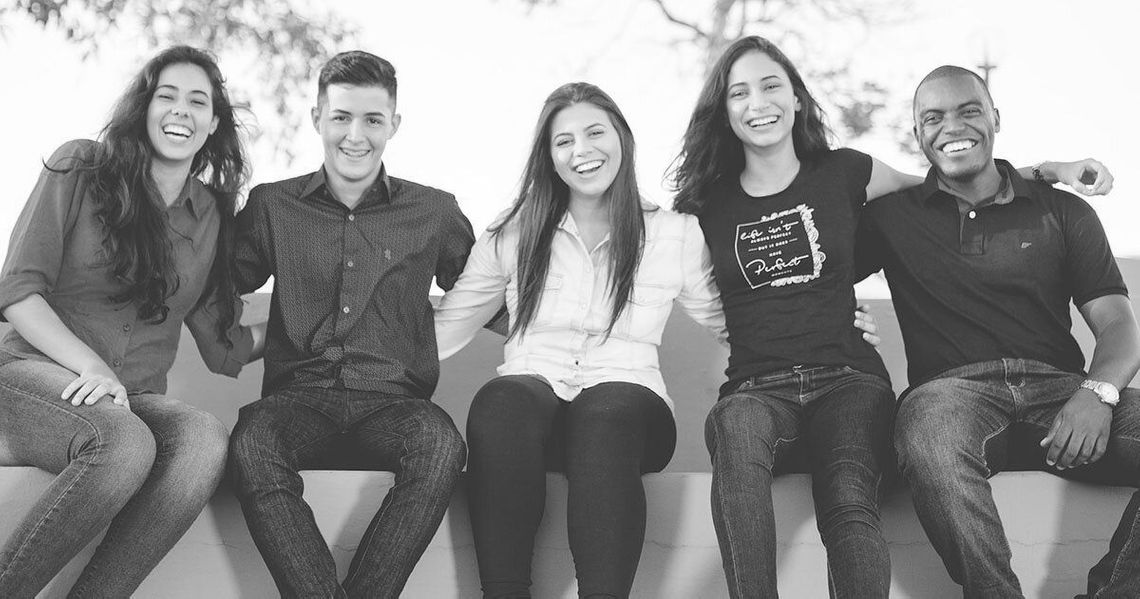

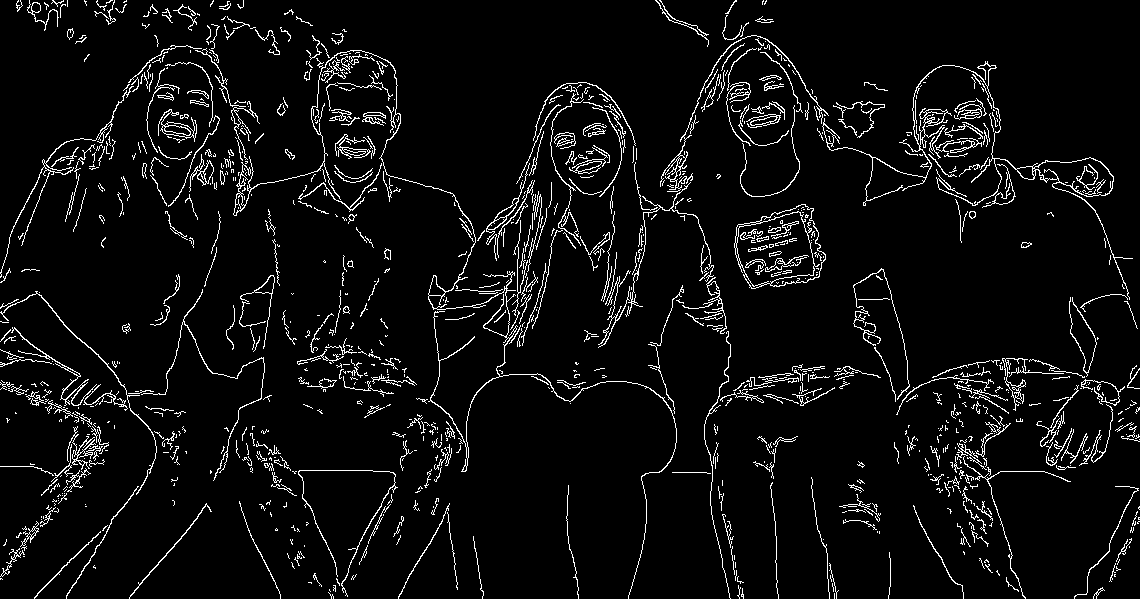

In [51]:
import cv2
from google.colab.patches import cv2_imshow  # Use this instead of cv2.imshow

img = cv2.imread('Faces.jpg', 0)  # grayscale

edges = cv2.Canny(img, 100, 200)

cv2_imshow( img)
cv2_imshow(edges)

cv2.waitKey(0)
cv2.destroyAllWindows()

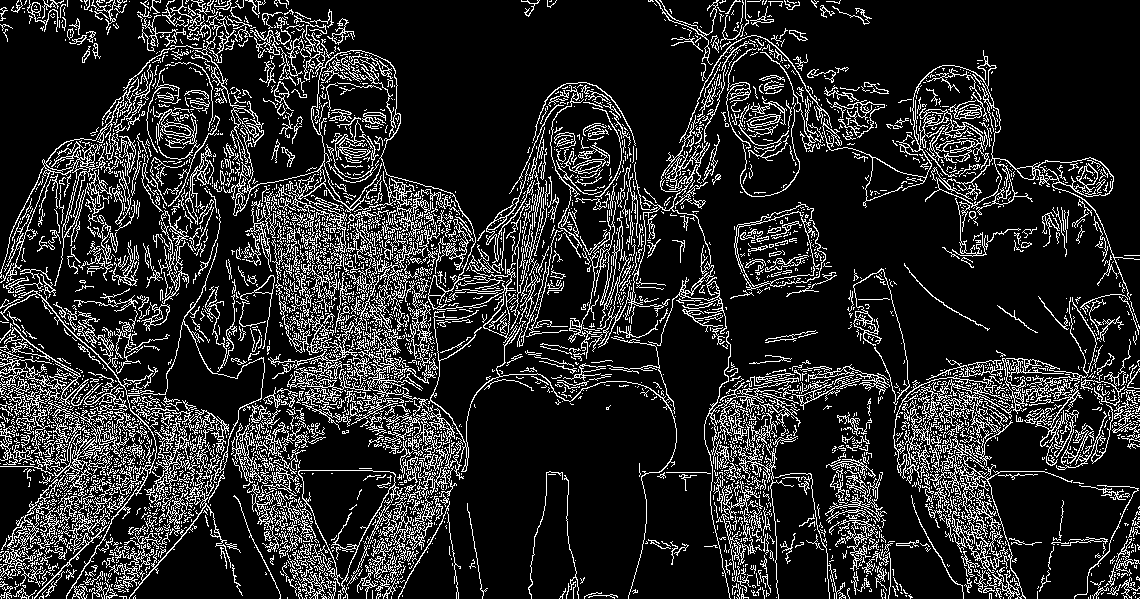

In [ ]:
# Low thresholds (more edges + noise)

edges = cv2.Canny(img, 30, 80)

cv2_imshow(edges)

cv2.waitKey(0)
cv2.destroyAllWindows()

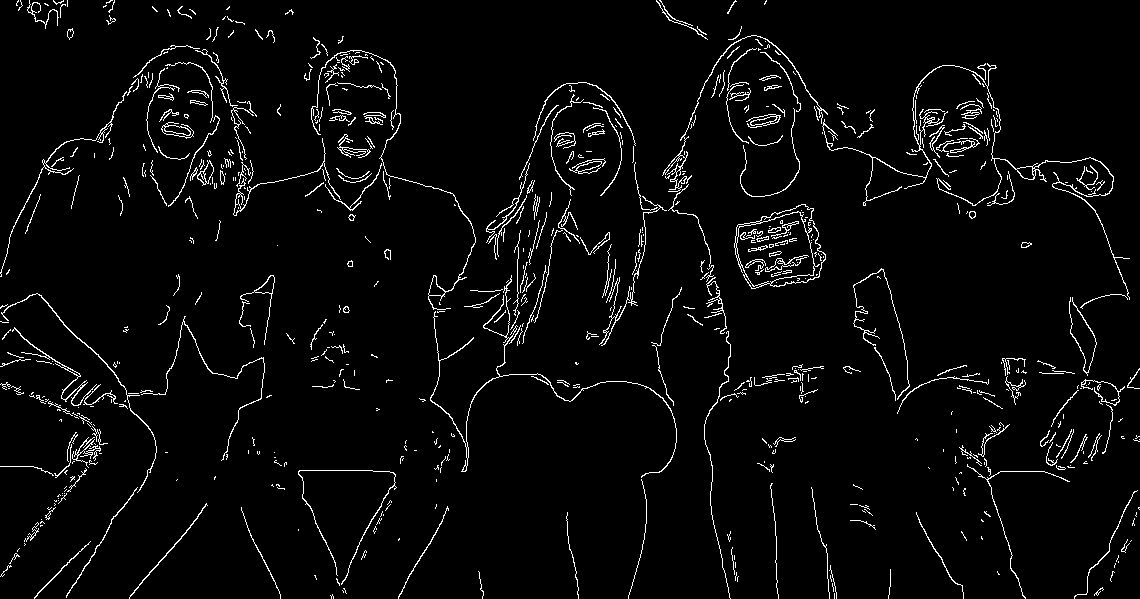

In [ ]:
# High thresholds (only strong edges)

edges = cv2.Canny(img, 150, 250)

cv2_imshow(edges)

cv2.waitKey(0)
cv2.destroyAllWindows()

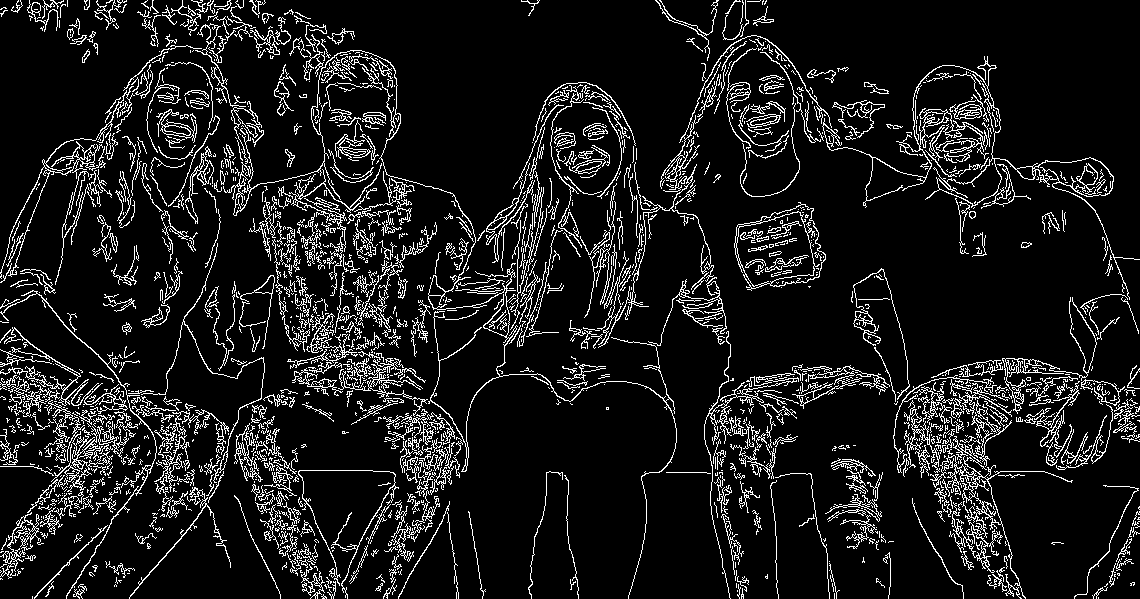

In [52]:
# Very high thresholds (almost empty)

edges = cv2.Canny(img, 50, 150)

cv2_imshow(edges)

cv2.waitKey(0)
cv2.destroyAllWindows()

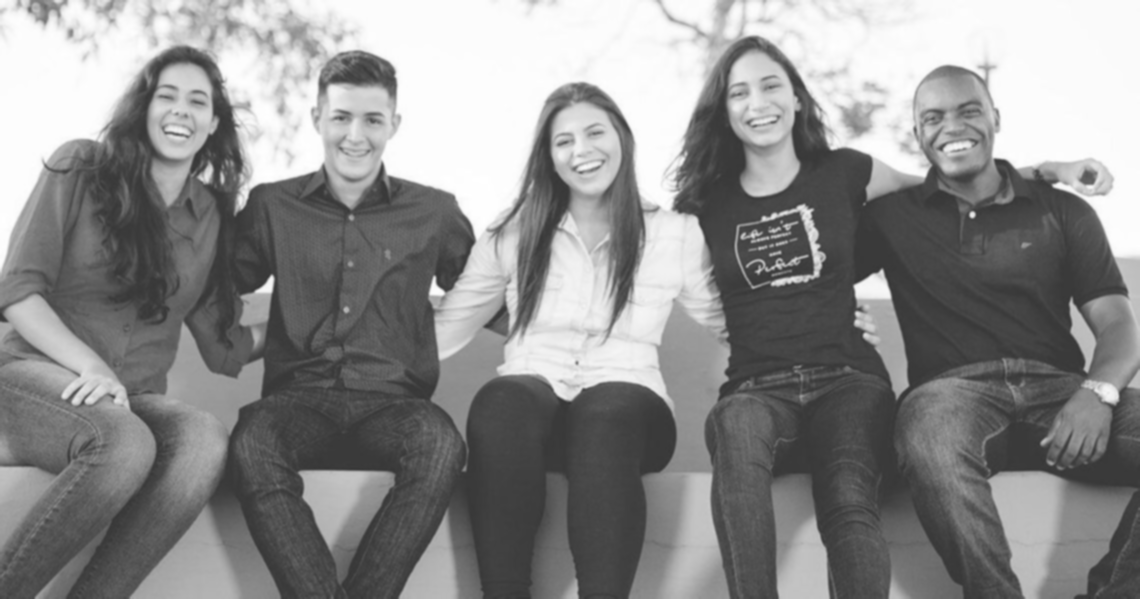

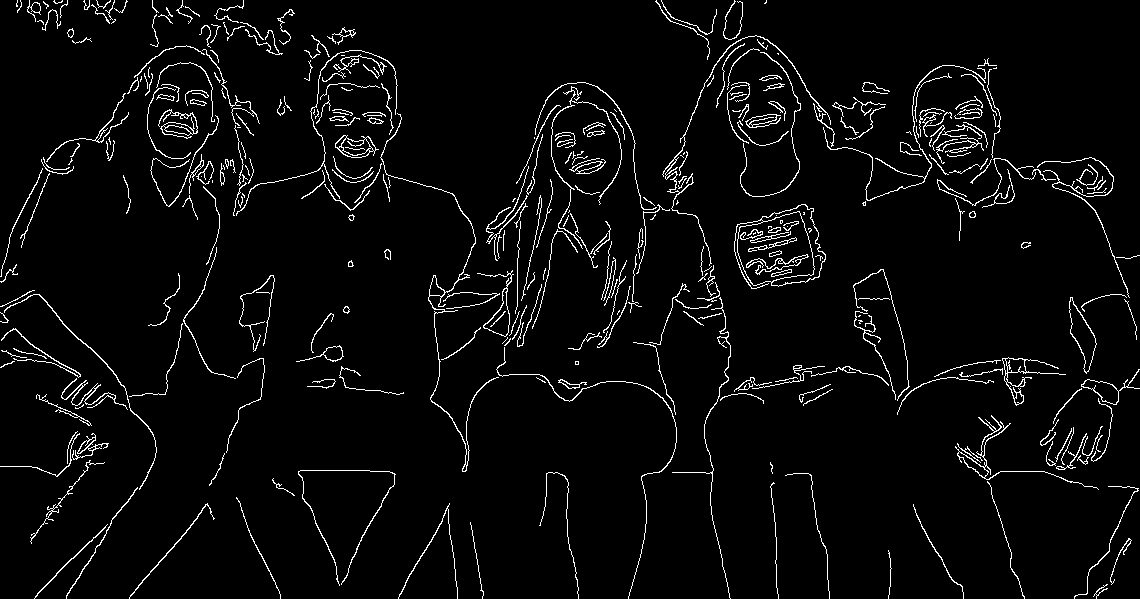

In [53]:
# Real-world tuning (best practice)

blur = cv2.GaussianBlur(img, (5,5), 0)
cv2_imshow(blur)

edges = cv2.Canny(blur, 50, 150)

cv2_imshow(edges)

cv2.waitKey(0)
cv2.destroyAllWindows()

Why blur first?

* Removes noise
* Makes edges cleaner
* More stable detection

Pro tip (important)

Most real systems use:

`blur → grayscale → Canny`

Because it gives stable and clean edges

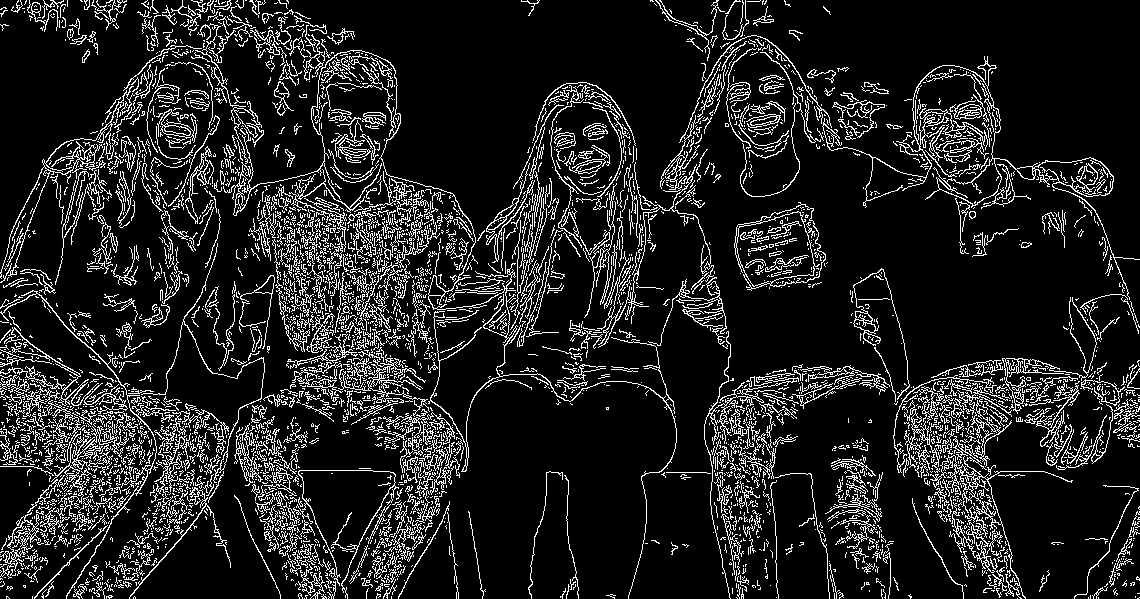

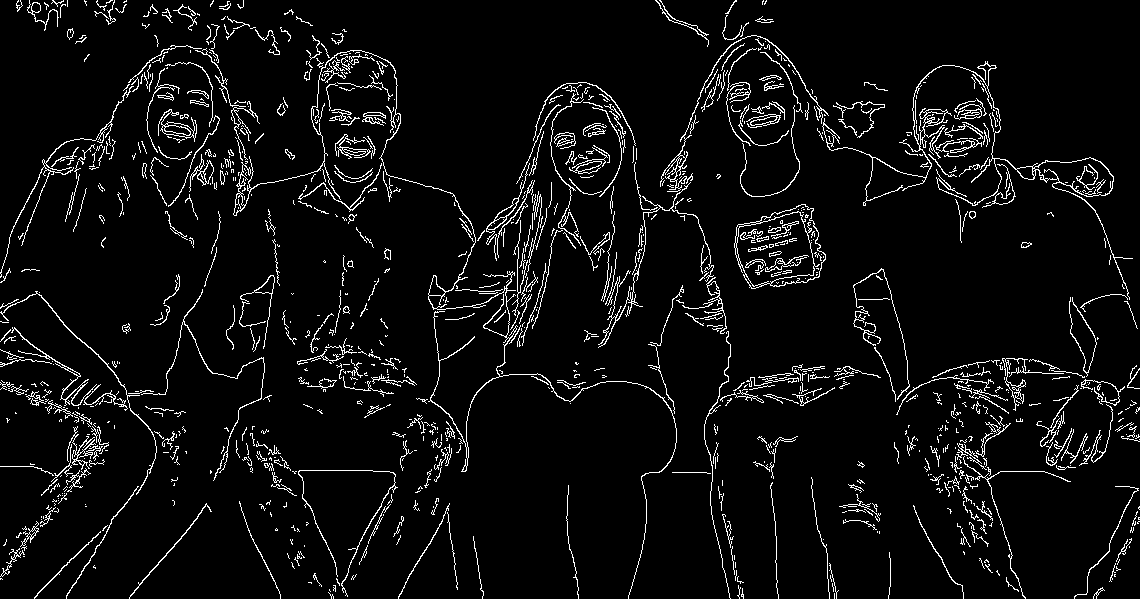

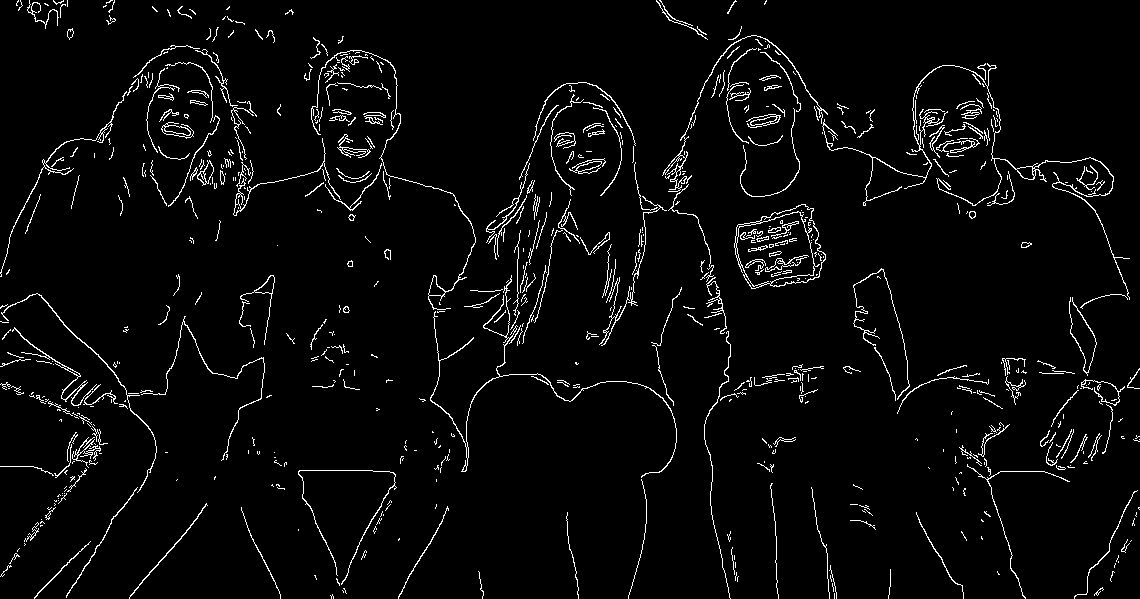

In [ ]:
# Bonus challenge

# Try this:

for t1, t2 in [(50,100), (100,200), (150,250)]:
    edges = cv2.Canny(img, t1, t2)
    cv2_imshow(edges)

# Compare results side-by-side

# Face Recognition
We will do face recognition in this article using something known as haar cascades. Haar Cascade is a machine learning-based approach where a lot of positive and negative images are used to train the classifier.

Positive images: These images contain the images which we want our classifier to identify.
Negative Images: Images of everything else, which do not contain the object we want to detect.

File Used:

* haarcascade_frontalface_default.xml

* haarcascade_eye.xml

Example: Python OpenCV Face Recognition

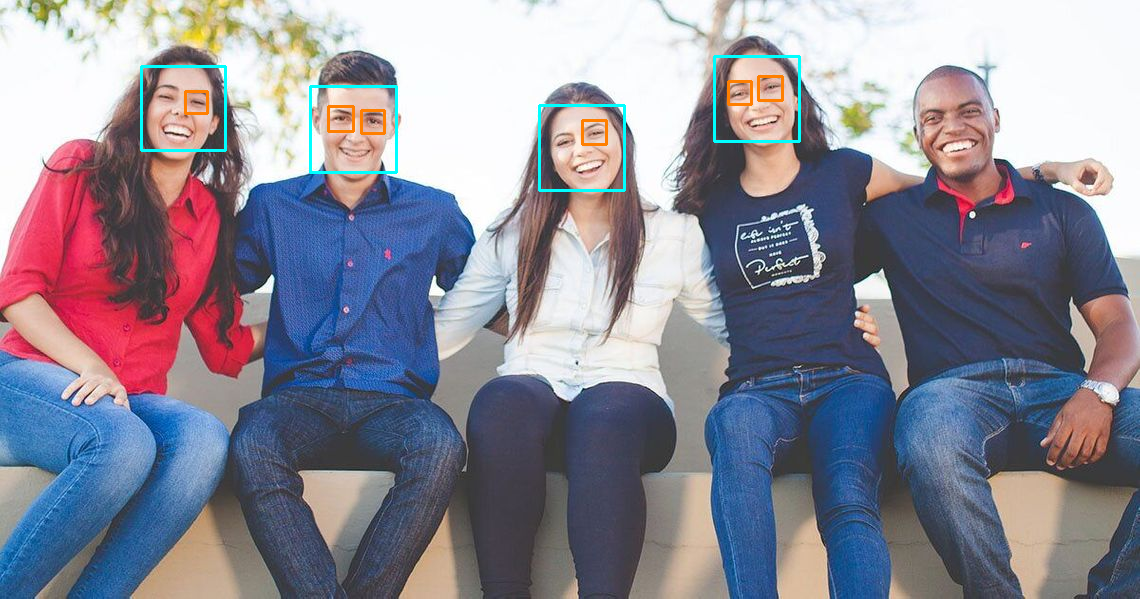

In [66]:
# Face Detection using Haar Cascade Algorithm
# read image from web

import cv2
from google.colab.patches import cv2_imshow  # Required for displaying images in Google Colab

# -----------------------------
# 1. Load pre-trained models
# -----------------------------
# Haar Cascade XML files contain trained data for detecting features like faces and eyes
face_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades + 'haarcascade_frontalface_default.xml'
)

eye_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades + 'haarcascade_eye.xml'
)

# -----------------------------
# 2. Read input image
# -----------------------------
# Load image
img = cv2.imread('Faces.jpg')

# If image is not found, stop execution
if img is None:
    print("Error: Image not found")
    exit()

# -----------------------------
# 3. Convert image to grayscale
# -----------------------------
# Haar Cascade works better on grayscale images because it reduces complexity
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# -----------------------------
# 4. Detect faces
# -----------------------------
# detectMultiScale scans the image at different scales to find faces
# face_cascade.detectMultiScale(image, scaleFactor, minNeighbors)
faces = face_cascade.detectMultiScale(gray, 1.3, 8)

'''
scaleFactor:
The image is repeatedly resized to detect faces of different sizes.
1.3 means: reduce image size by 30% each step

  Effect:
    Smaller value (e.g., 1.05):
      More accurate
      Slower
    Larger value (e.g., 1.4–1.5):
      Faster
      Less accurate


minNeighbors:
It controls how many “neighbor rectangles” are needed before confirming a face.

  Effect:
    Higher value (e.g., 6–8):
      Fewer false positives
      Might miss some faces
    Lower value (e.g., 2–3):
      More false detections
      Detects more faces (even weak ones)

'''
# -----------------------------
# 5. Loop through each detected face
# -----------------------------
for (x, y, w, h) in faces:

    # Draw rectangle around detected face
    cv2.rectangle(img, (x, y), (x + w, y + h), (255, 255, 0), 2)

    # Crop face region from grayscale and color image
    roi_gray = gray[y:y + h, x:x + w]
    roi_color = img[y:y + h, x:x + w]

    # -----------------------------
    # 6. Detect eyes inside face region
    # -----------------------------
    eyes = eye_cascade.detectMultiScale(roi_gray)

    # Draw rectangles around detected eyes
    for (ex, ey, ew, eh) in eyes:
        cv2.rectangle(roi_color, (ex, ey), (ex + ew, ey + eh), (0, 127, 255), 2)

# -----------------------------
# 7. Display final output image
# -----------------------------
#cv2.imshow('img', img)
cv2_imshow(img)
cv2.waitKey(0)
cv2.destroyAllWindows()

In [ ]:
# Face Detection using Haar Cascade Algorithm
# OpenCV program to detect face in real time from Camera
# import libraries of python OpenCV
# where its functionality resides

# Import OpenCV library (used for image and video processing)
import cv2

# -----------------------------------------
# 1. Load pre-trained Haar Cascade models
# -----------------------------------------
# These XML files contain trained data to detect faces and eyes
# Face detector
face_cascade = cv2.CascadeClassifier('haarcascade_frontalface_default.xml')

# Eye detector
eye_cascade = cv2.CascadeClassifier('haarcascade_eye.xml')

# -----------------------------------------
# 2. Start webcam (0 = default camera)
# -----------------------------------------
cap = cv2.VideoCapture(0)

# -----------------------------------------
# 3. Start infinite loop for real-time video
# -----------------------------------------
while True:

    # Read frame from webcam
    ret, img = cap.read()

    # Check if frame is captured correctly
    if not ret:
        break

    # -----------------------------------------
    # 4. Convert frame to grayscale
    # -----------------------------------------
    # Haar cascade works better on grayscale images
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # -----------------------------------------
    # 5. Detect faces in the image
    # -----------------------------------------
    faces = face_cascade.detectMultiScale(gray, 1.3, 5)

    # -----------------------------------------
    # 6. Loop through each detected face
    # -----------------------------------------
    for (x, y, w, h) in faces:

        # Draw rectangle around face
        cv2.rectangle(img, (x, y), (x + w, y + h), (255, 255, 0), 2)

        # Crop face region (Region of Interest - ROI)
        roi_gray = gray[y:y + h, x:x + w]
        roi_color = img[y:y + h, x:x + w]

        # -----------------------------------------
        # 7. Detect eyes inside the face region
        # -----------------------------------------
        eyes = eye_cascade.detectMultiScale(roi_gray)

        # Draw rectangle around each eye
        for (ex, ey, ew, eh) in eyes:
            cv2.rectangle(roi_color,
                          (ex, ey),
                          (ex + ew, ey + eh),
                          (0, 127, 255),
                          2)

    # -----------------------------------------
    # 8. Show output frame
    # -----------------------------------------
    cv2.imshow('Face & Eye Detection', img)

    # -----------------------------------------
    # 9. Exit when ESC key is pressed
    # -----------------------------------------
    k = cv2.waitKey(30) & 0xff
    if k == 27:  # 27 = ESC key
        break

# -----------------------------------------
# 10. Release resources
# -----------------------------------------
cap.release()
cv2.destroyAllWindows()

In [ ]:
import cv2  # Import OpenCV library

# Open the default camera (0 = primary webcam)
cap = cv2.VideoCapture(0)

# Check if the camera opened successfully
if not cap.isOpened():
    print("Error: Cannot access camera")
    exit()

img_counter = 0  # Counter to name saved images

while True:
    ret, frame = cap.read()  # Capture frame-by-frame

    # If frame was not captured correctly, exit loop
    if not ret:
        print("Failed to grab frame")
        break

    # Display the captured frame in a window
    cv2.imshow("Camera", frame)

    key = cv2.waitKey(1)  # Wait for a key press (1 ms delay)

    # If ESC key is pressed (ASCII 27), exit the program
    if key % 256 == 27:
        print("Closing...")
        break

    # If SPACE key is pressed (ASCII 32), save the image
    elif key % 256 == 32:
        img_name = f"image_{img_counter}.png"  # Create filename
        cv2.imwrite(img_name, frame)  # Save the image to disk
        print(f"{img_name} saved!")
        img_counter += 1  # Increase counter for next image

# Release the camera resource
cap.release()

# Close all OpenCV windows
cv2.destroyAllWindows()